In [316]:
import numpy as np, cv2, math
import sys
import matplotlib.pyplot as plt

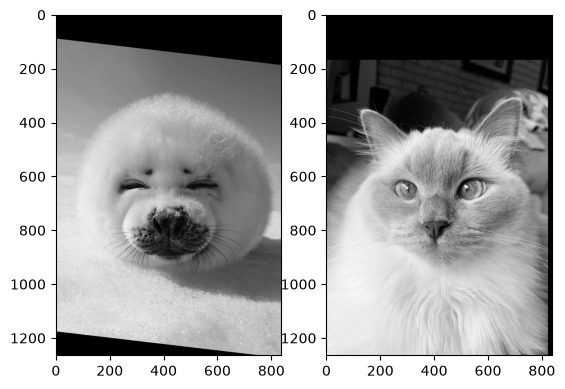

In [317]:
#https://github.com/OlaPietka/Hybrid-Images/tree/main
#fonte das imagens
img2 = cv2.imread("../imgs/jula_aligned.jpg", cv2.IMREAD_GRAYSCALE)

img1 = cv2.imread("../imgs/seal_aligned.jpg",  cv2.IMREAD_GRAYSCALE)
assert img1 is not None
assert img2 is not None

plt.subplot(1, 2, 1)
plt.imshow(img1, "gray")
plt.subplot(1, 2, 2)
plt.imshow(img2, "gray")

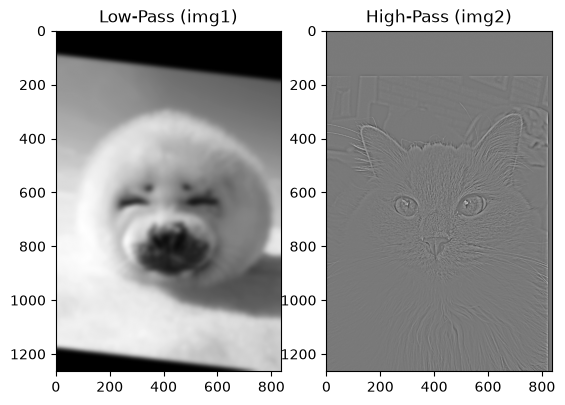

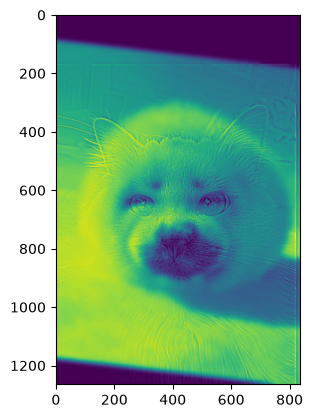

In [318]:
assert img1 is not None
assert img2 is not None

ksize_low = 51
ksize_high = 23
img1_f = img1.astype(np.float32)
img2_f = img2.astype(np.float32)

img_low = cv2.GaussianBlur(img1_f, (ksize_low, ksize_low), 0)

img_high = img2_f - cv2.GaussianBlur(img2_f, (ksize_high, ksize_high), 0)

img_high_display = np.clip(img_high + 128, 0, 255).astype(np.uint8)
img_low_display = np.clip(img_low, 0, 255).astype(np.uint8)

plt.subplot(1, 2, 1)
plt.imshow(img_low_display, cmap="gray")
plt.title("Low-Pass (img1)")

plt.subplot(1, 2, 2)
plt.imshow(img_high_display, cmap="gray")
plt.title("High-Pass (img2)")

plt.show()
img_hybrid = img_low + img_high
img_disp = np.clip(img_hybrid, 0, 255).astype(np.uint8)
plt.subplot(1, 1, 1)
plt.imshow(img_disp)

# agora, por fft

In [319]:
dft = np.fft.fft2(np.float32(img1))
dft_shiftado = np.fft.fftshift(dft)



magnitude_spectrum = 20*np.log(np.abs(dft_shiftado))

dft2 = np.fft.fft2(np.float32(img2))
dft_shiftado2 = np.fft.fftshift(dft2)



magnitude_spectrum2 = 20*np.log(np.abs(dft_shiftado2))

# dft2 = np.fft.fft2(np.float32(img2))
# dft_shiftado2 = np.fft.fftshift(dft2)

# magnitude_spectrum2 = 20*np.log(cv2.magnitude(dft_shiftado2[:,:,0], dft_shiftado2[:,:,1]))

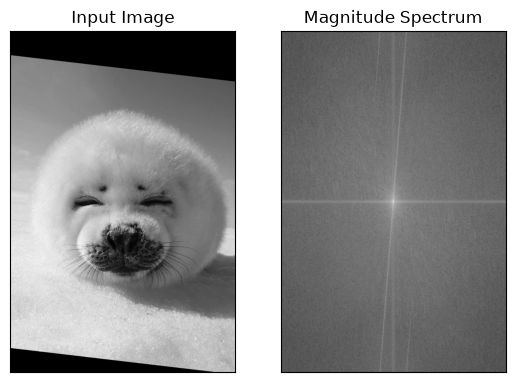

In [320]:
plt.subplot(121),plt.imshow(img1, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

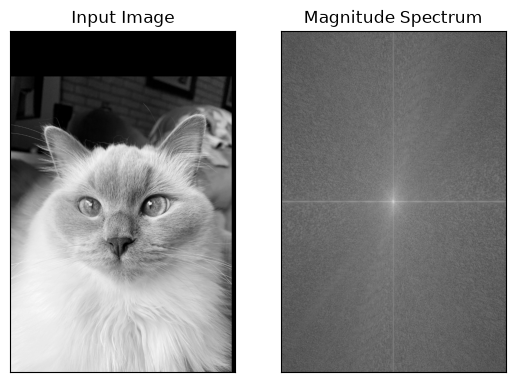

In [321]:
plt.subplot(121),plt.imshow(img2, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum2, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

In [ ]:
# places a notch reject circle of radius r centered in point(x,y) in the mask
def place_notch_reject(Hmask, x, y, r = 10):

    iniciox = x - r
    inicioy = y - r

    sigma = r / 2.0

    for i in range(0,2*r+1):
        for j in range (0,2*r+1):
            if ((iniciox + i) >= Hmask.shape[0] or (iniciox + i) > Hmask.shape[0] < 0):
                continue

            if ((inicioy + j) >= Hmask.shape[1] or (inicioy + j) > Hmask.shape[1] < 0):
                continue

            if (np.sqrt((r - i)** 2 + (r - j)** 2) <= r):
            #    Hmask[iniciox + i][inicioy + j] = 0.0
                dist = np.sqrt((r-1)**2 + (r-j)**2)
                Hmask[iniciox + i][inicioy + j] *= (1.0 - np.exp(-(dist**2) / (2 * sigma**2)))

    iniciox -= 2 * (x - int(Hmask.shape[0]/2))
    inicioy -= 2 * (y - int(Hmask.shape[1]/2))

    for i in range(0,2*r+1):
            for j in range (0,2*r+1):
                if ((iniciox + i) >= Hmask.shape[0] or (iniciox + i) > Hmask.shape[0] < 0):
                    continue
    
                if ((inicioy + j) >= Hmask.shape[1] or (inicioy + j) > Hmask.shape[1] < 0):
                    continue
    
                if (np.sqrt((r - i)** 2 + (r - j)** 2) <= r):
                #    Hmask[iniciox + i][inicioy + j] = 0.0
                    dist = np.sqrt((r-i)**2 + (r-j)**2)
                    Hmask[iniciox + i][inicioy + j] *= (1.0 - np.exp(-(dist**2) / (2 * sigma**2)))

In [323]:
def place_notch_reject_interactive(shape, Hmask, x, y, r = 10):
    x, y = y, x
    x = int(shape[0]/2)-x
    y = int(shape[1]/2)+y
    # iniciox = x - r
    # inicioy = y - r
    
    # for i in range(0,2*r+1):
    #     for j in range (0,2*r+1):
    #         if ((iniciox + i) >= Hmask.shape[0] or (iniciox + i) > Hmask.shape[0] < 0):
    #             pass

    #         if ((inicioy + j) >= Hmask.shape[1] or (inicioy + j) > Hmask.shape[1] < 0):
    #             pass

    #         if (np.sqrt((r - i)** 2 + (r - j)** 2) <= r):
    #             Hmask[iniciox + i][inicioy + j] = 0.0
    place_notch_reject(Hmask, x, y, r)

    x -= 2 * (x - int(shape[0]/2))
    y -= 2 * (y - int(shape[1]/2))

    place_notch_reject(Hmask, x, y, r)
    

    # for i in range(0,2*r+1):
    #         for j in range (0,2*r+1):
    #             if ((iniciox + i) >= Hmask.shape[0] or (iniciox + i) > Hmask.shape[0] < 0):
    #                 continue
    
    #             if ((inicioy + j) >= Hmask.shape[1] or (inicioy + j) > Hmask.shape[1] < 0):
    #                 continue
    
    #             # if (np.sqrt(((iniciox + i) - x)**2 + ((inicioy + j) - y)**2) <= r):
    #             #     pass
    #             if (np.sqrt((r - i)** 2 + (r - j)** 2) <= r):
    #                 Hmask[iniciox + i][inicioy + j] = 0.0


    return Hmask

In [324]:
Hmask = np.ones(img1.shape, dtype=np.float32)

Hmask2 = np.zeros(img2.shape, dtype=np.float32)

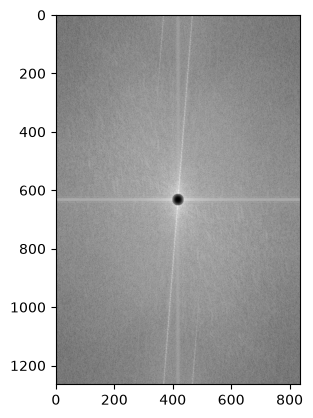

In [325]:
Hmask = place_notch_reject_interactive(img1.shape, Hmask, 0,0, 20)


plt.imshow(Hmask*magnitude_spectrum, cmap='gray')

Hmask2 = (1.0 - Hmask)

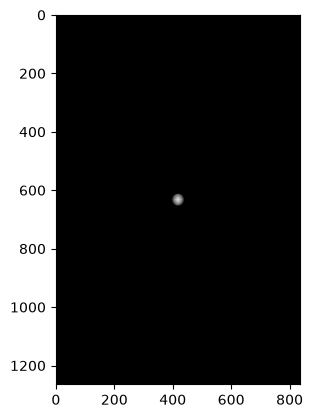

In [326]:


plt.imshow(Hmask2*magnitude_spectrum2, cmap='gray')

In [327]:
final_freq = Hmask2*dft_shiftado2 + Hmask*dft_shiftado


# plt.imshow(final_freq, cmap = 'gray')




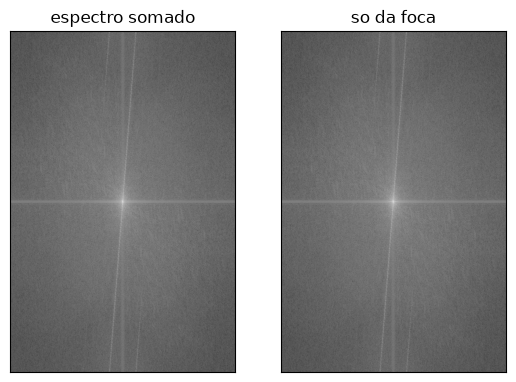

In [328]:
plt.subplot(121),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('espectro somado'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(Hmask2*magnitude_spectrum2 + Hmask*magnitude_spectrum, cmap = 'gray')
# + Hmask*magnitude_spectrum
plt.title('so da foca'), plt.xticks([]), plt.yticks([])
plt.show()

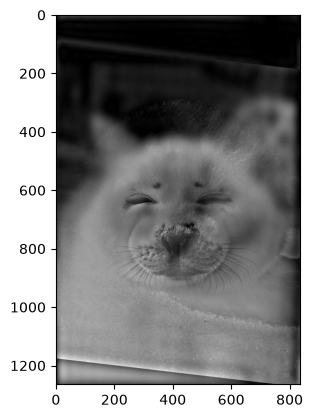

In [329]:
centralizado = np.fft.ifftshift(final_freq)
final = np.fft.ifft2(centralizado)
result = np.abs(final)

#centralizado = np.fft.ifftshift(i)
# final = np.fft.ifft2(dft)
# result = np.abs(final)

# plt.imshow(result, cmap = 'gray')

plt.imshow(result, cmap='gray')

